In [9]:
#Plotting library
import matplotlib.pyplot as plt

#Data library...like Excel for python
import pandas as pd

#Numerical function library
import numpy as np

#Operating system, 'glob' library - for getting list of files in directory
import os, glob

#Jupyter command for generating Matplotlib plots inline with the commands in the notebook
%matplotlib inline
#%matplotlib notebook

import seaborn as sns
import scipy
import math
from IPython.display import set_matplotlib_formats
# matplotlib_inline.backend_inline.set_matplotlib_formats()
set_matplotlib_formats('retina')

# plt.style.use('seaborn-whitegrid')

#set the working directory (where the data you want to work up is stored)
topwd='/Users/dcollins/Library/CloudStorage/OneDrive-NLR/20260727 -3tAGSD200NMGRID_SEEDAFTER'

#change whatever the current working space is to the desired space, just set above
os.chdir(topwd)

#check that directory is right
os.getcwd()

/var/folders/v7/gxvkh6fs2bl1s2vfh9653l900000gr/T/ipykernel_39289/1351931862.py:22: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  set_matplotlib_formats('retina')


'/Users/dcollins/Library/CloudStorage/OneDrive-NLR/20260727 -3tAGSD200NMGRID_SEEDAFTER'

In [17]:
#glob will find anything with string given and put it into filelist
filelist = sorted(glob.glob('*FZ*.mpt'))
#filelist='20260723_3Tagsd200nmgrid_seedafter_RZ_CV_inital_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_1sun_after_cp1_cv1_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_dark_after_cp2_cv2_C01.mpt',
filelist

['20260723_3Tagsd200nmgrid_seedafter1_FZ_CE_ccloth_re_agagcl_10mlmin_1SUN_after_cp3_CV3_C01.mpt',
 '20260723_3Tagsd200nmgrid_seedafter1_FZ_CE_ccloth_re_agagcl_10mlmin_1sun_AFTER_cp4_cv4_C01.mpt',
 '20260723_3Tagsd200nmgrid_seedafter1_FZ_CE_ccloth_re_agagcl_10mlmin_1sun_after_cp2_CV2_3_C01.mpt',
 '20260723_3Tagsd200nmgrid_seedafter1_FZ_CE_ccloth_re_agagcl_10mlmin_dark_after_cp2_geis2_C01.mpt',
 '20260723_3Tagsd200nmgrid_seedafter1_FZ_CE_ccloth_re_agagcl_1sun_after_cp1_cv1_C01.mpt',
 '20260723_3Tagsd200nmgrid_seedafter1_FZ_CE_ccloth_re_agagcl_dark_CV_inital_2_C01.mpt',
 '20260723_3Tagsd200nmgrid_seedafter1_FZ_CE_ccloth_re_agagcl_dark_CV_inital_C01.mpt']

In [82]:
filelist = [
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_part2_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_part3_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_dark_FZ_n1ma_CP2_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_dark_FZ_n1ma_CP2_PROTECTION_LONG_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_dark_FZ_n1ma_CP2_PROTECTION_LONG_2_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_dark_FZ_n1ma_CP2_PROTECTION_LONG_3_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_dark_FZ_n1ma_CP2_PROTECTION_LONG_4_C01.mpt',
 '20260811_3TAgsdgrid_aglayer_803dep_ce_ccloth2_re_agagcl_withco2flow_8mlmin_1sun_FR_n3mA_CP_C01.mpt'
           ]

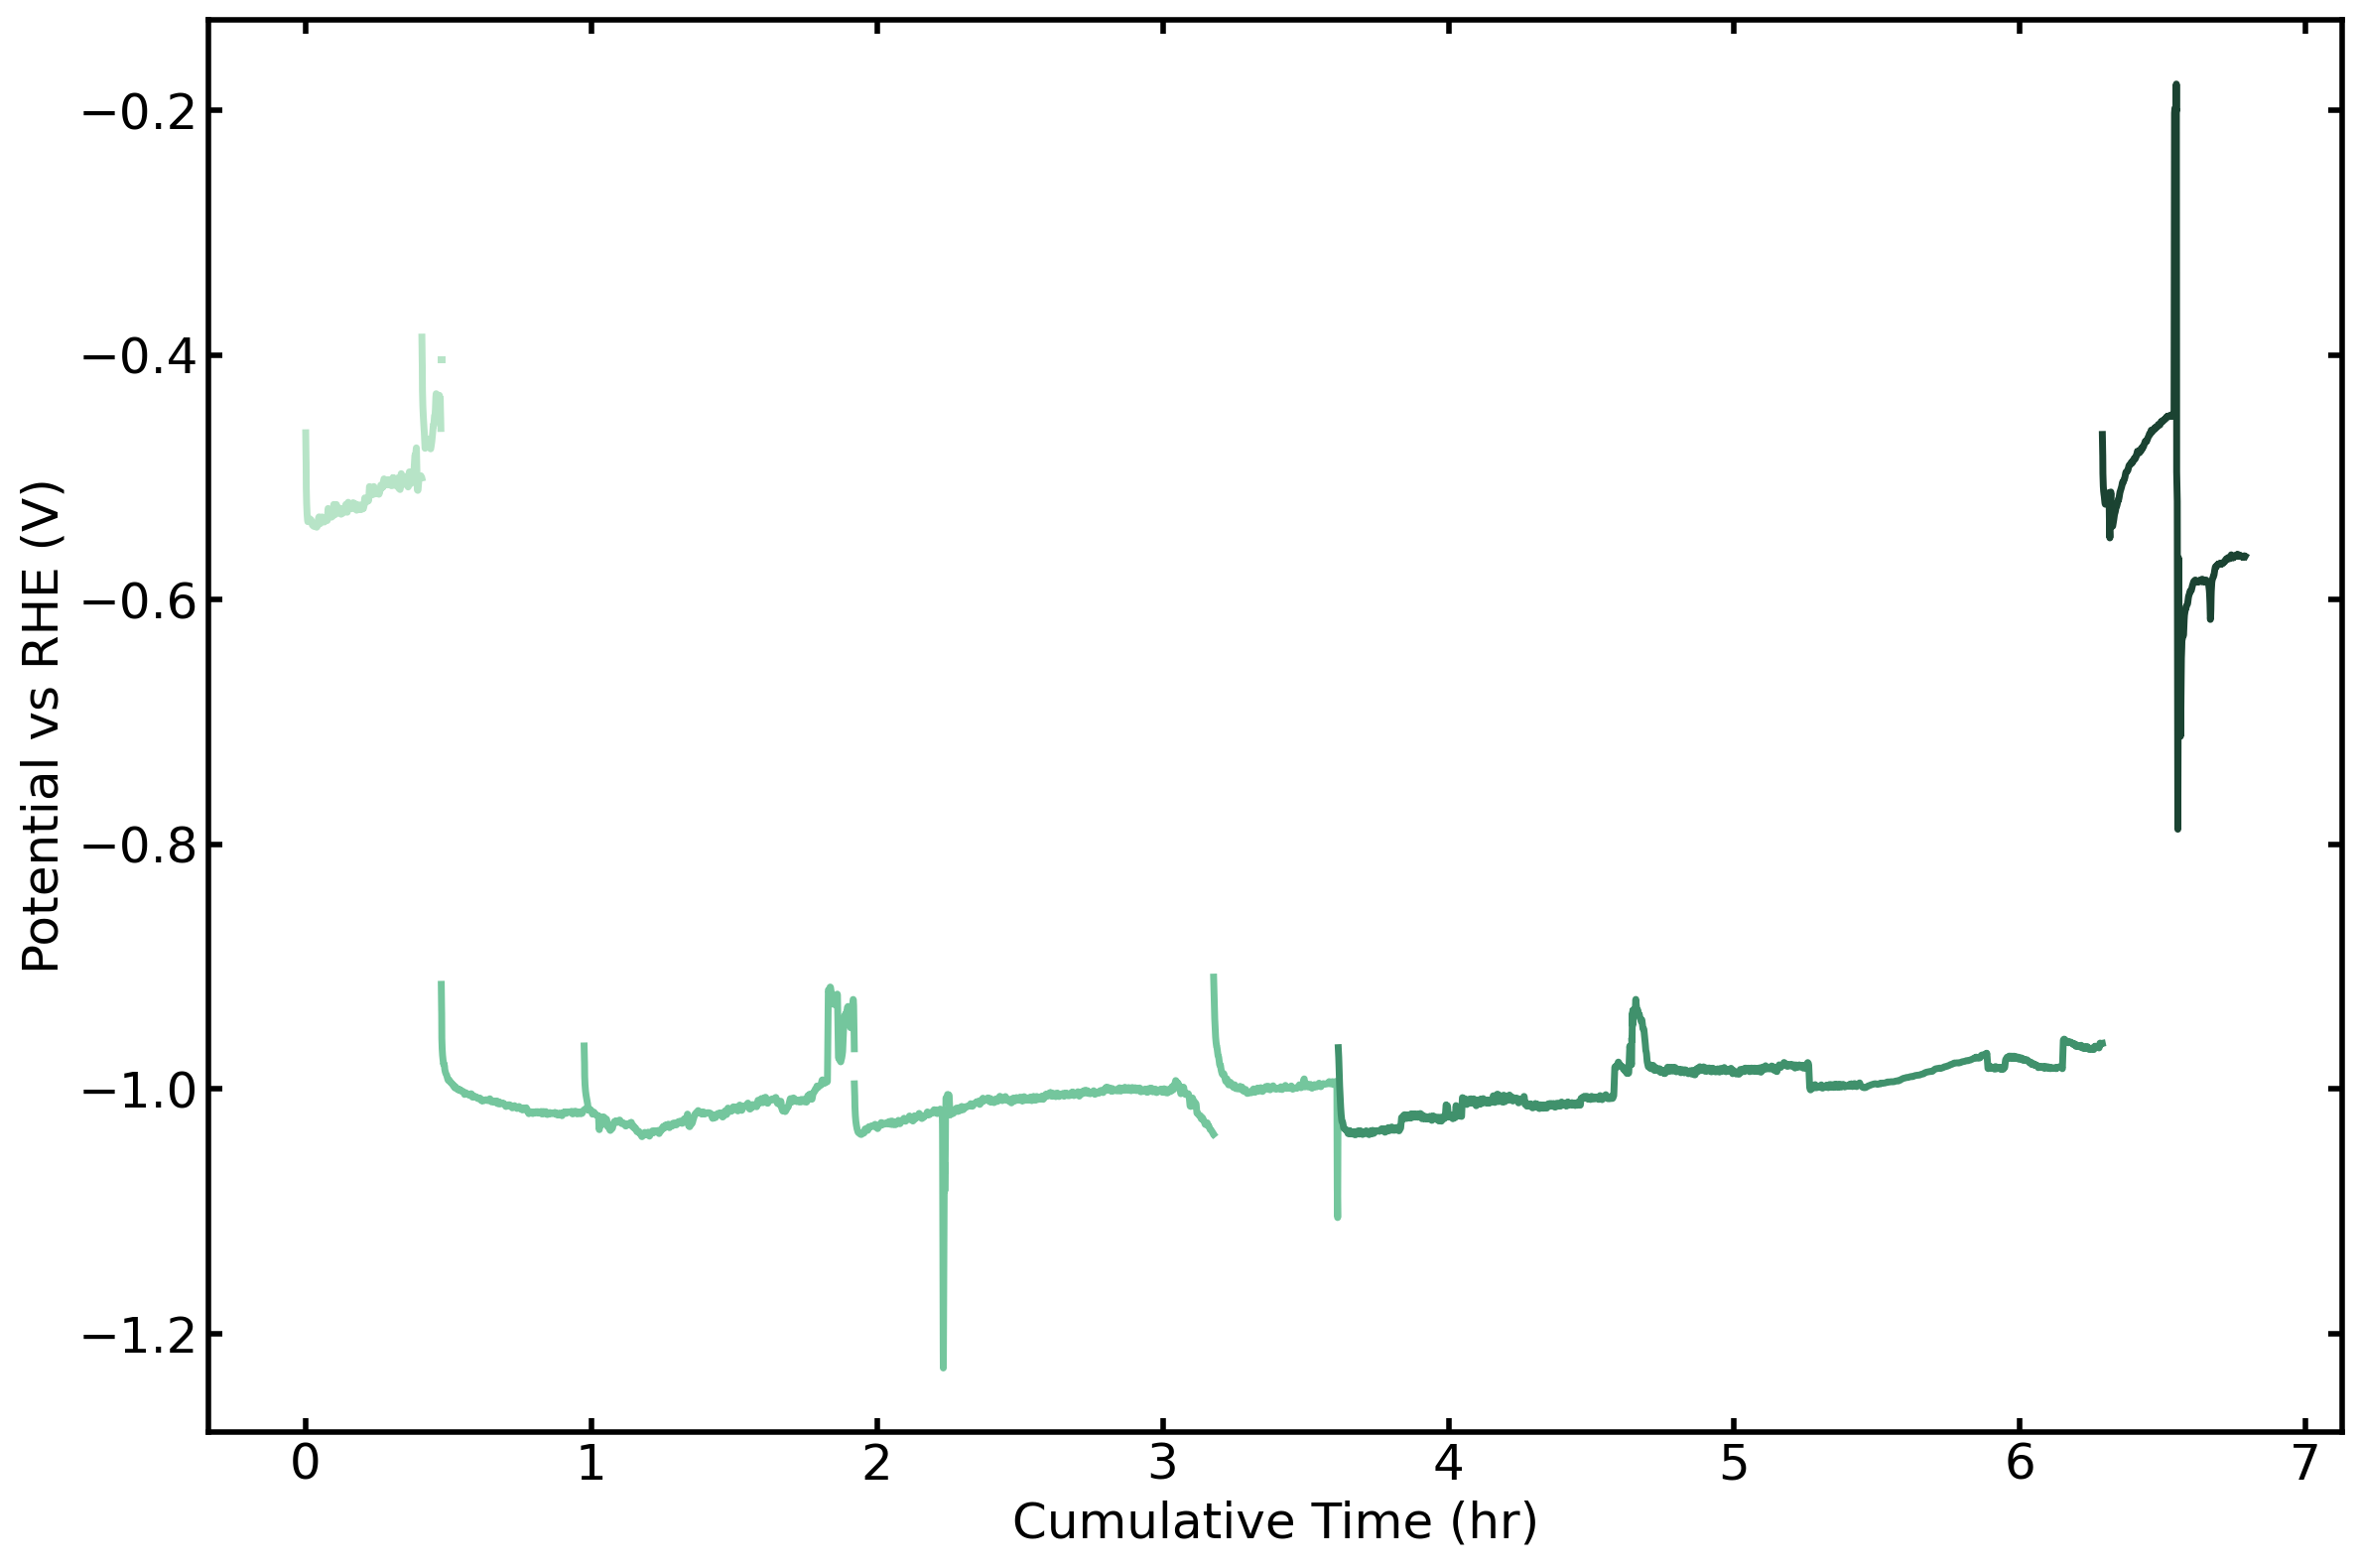

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import io
import os

# --- Plotting Setup ---
time_offset_hours = 0.0

plot_labels = [
    '-3 mA light FR',
    '_nolegend_',
    '_nolegend_',
    '-1 mA dark FZ',
    '-1 mA dark FZ',
    '_nolegend_',
    '_nolegend_',
    '_nolegend_',
    '-3 mA light FR',
    '_nolegend_',
    '_nolegend_',
]

# Setting our figure size
plt.figure(figsize=(12, 8))
plt.grid(False)

# Standard reference electrode potential and pH conversions
ref = 0.197     # Standard reference electrode potential
pH = 6.8        # pH of the solution
refi = ref + 0.059 * pH  # Conversion factor to RHE (V)

# Filtering & Smoothing Parameters
VALID_VOLTAGE_MIN = -1.9
VALID_VOLTAGE_MAX = 0.0
WINDOW_SIZE = 20
colors = ['#b7e4c7','#74c69d','#74c69d', '#74c69d',]
colors = ['#b7e4c7','#74c69d','#40916c', '#1b4332']
cmap = ['#b7e4c7','#b7e4c7','#b7e4c7', '#74c69d','#74c69d','#74c69d','#74c69d','#40916c', '#1b4332','b', 'g', 'm', 'm', 'm', 'c', 'y']

# --- Plotting Loop with Filtering & Smoothing ---
for jj in range(len(filelist)):
    skip = 54 
    
    # 1. Read your actual data file
    df = pd.read_csv(filelist[jj], skiprows=skip, encoding="ISO-8859-1", delimiter='\t')
    
    # Step 1: Filter out invalid voltage readings BEFORE smoothing
    df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
    
    # Step 2: Calculate the smoothed voltage on the FILTERED data
    df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(window=WINDOW_SIZE, center=True, min_periods=1).mean()
    
    # Step 3: Plot the cleaned and smoothed data
    # FIX 1: We calculate time using df_filtered so the row count matches voltage_smooth
    current_time_hours = df_filtered['time/s'] / 3600
    x_values = current_time_hours + time_offset_hours
    
    current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj}'
    
    # Plot the smoothed data (thicker, solid line)
    # FIX 2: Removed [jj] index from current_label to pass the correct string
    plt.plot(
        x_values, 
        df_filtered['voltage_smooth'] + refi, 
        color=cmap[jj % len(cmap)], 
        linewidth=2.5, 
        label=current_label
    )
    
    # Update the offset for the next file based on the max time in the filtered data
    if not current_time_hours.empty:
        time_offset_hours += current_time_hours.max()

# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend()
plt.tight_layout()
plt.tight_layout()
plt.savefig("wholetime_CP_FR_CP.pdf", format="pdf", bbox_inches="tight")
plt.show()


In [90]:
filelist2 = [
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_part2_C01.mpt',
 '20260811_3TAgsdgrid_aglayer_803dep_ce_ccloth2_re_agagcl_withco2flow_8mlmin_1sun_FR_n3mA_CP_C01.mpt',
           ]

Filtering out data points outside the range: -10.0V to 0V


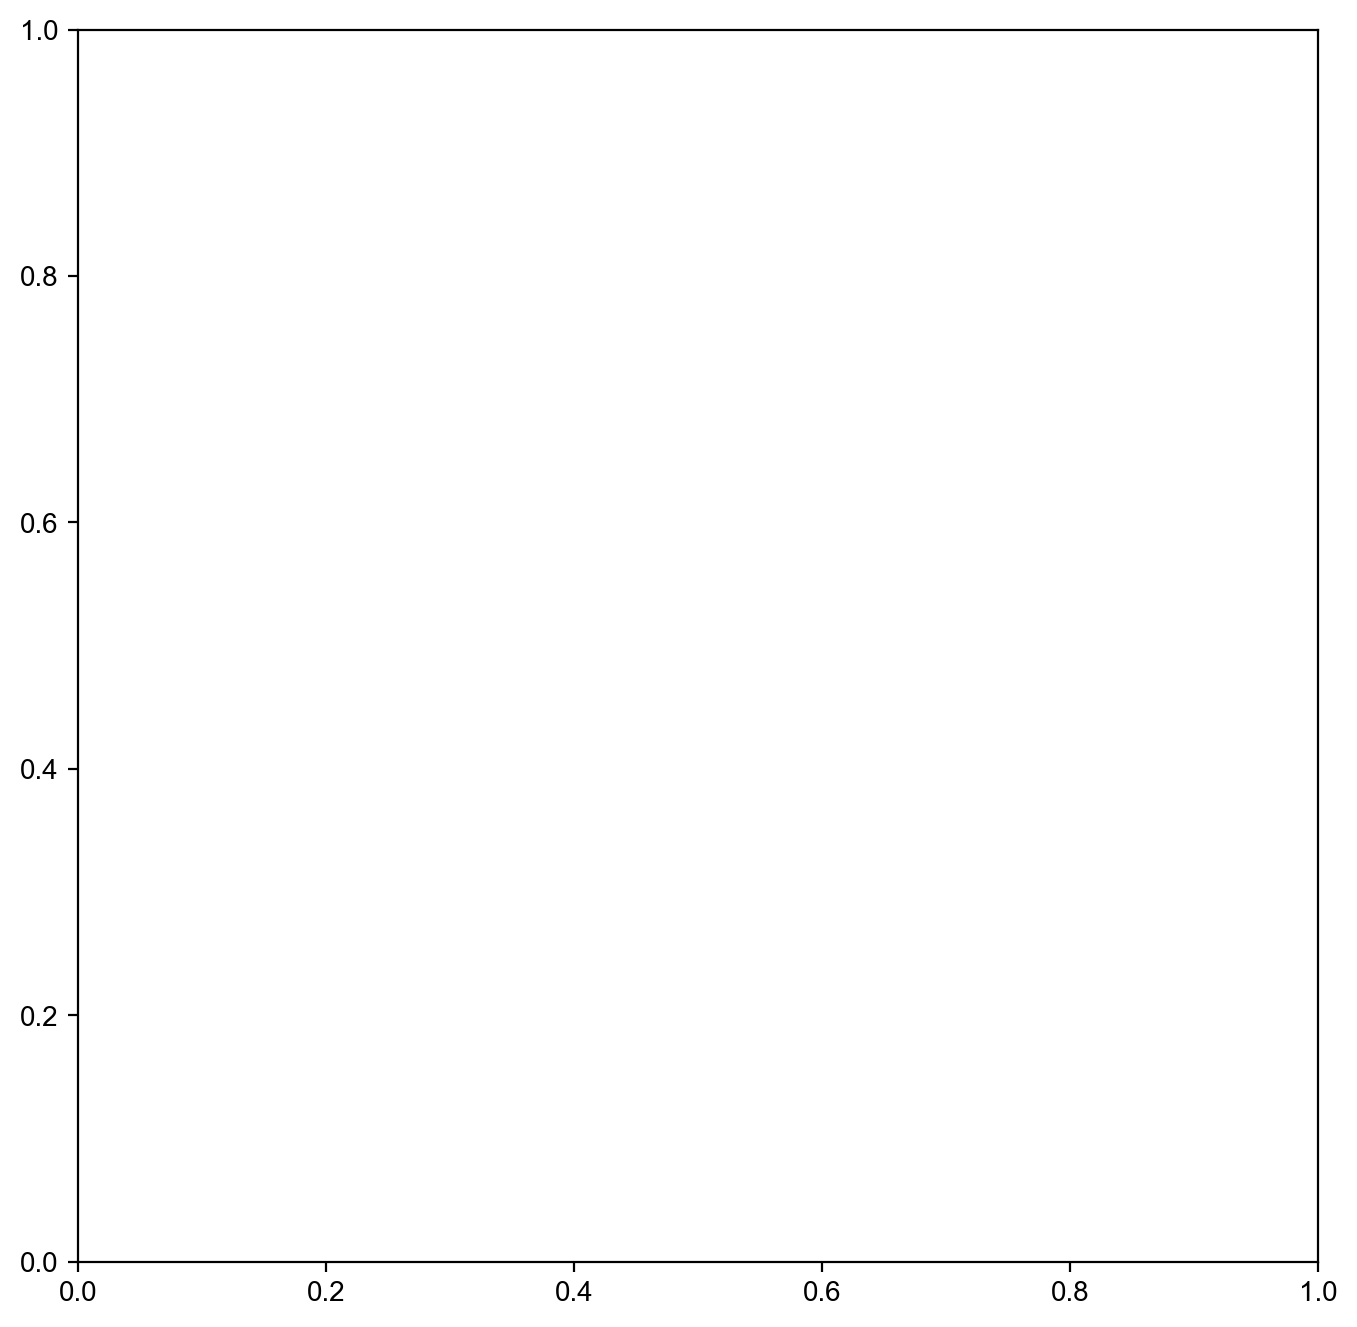

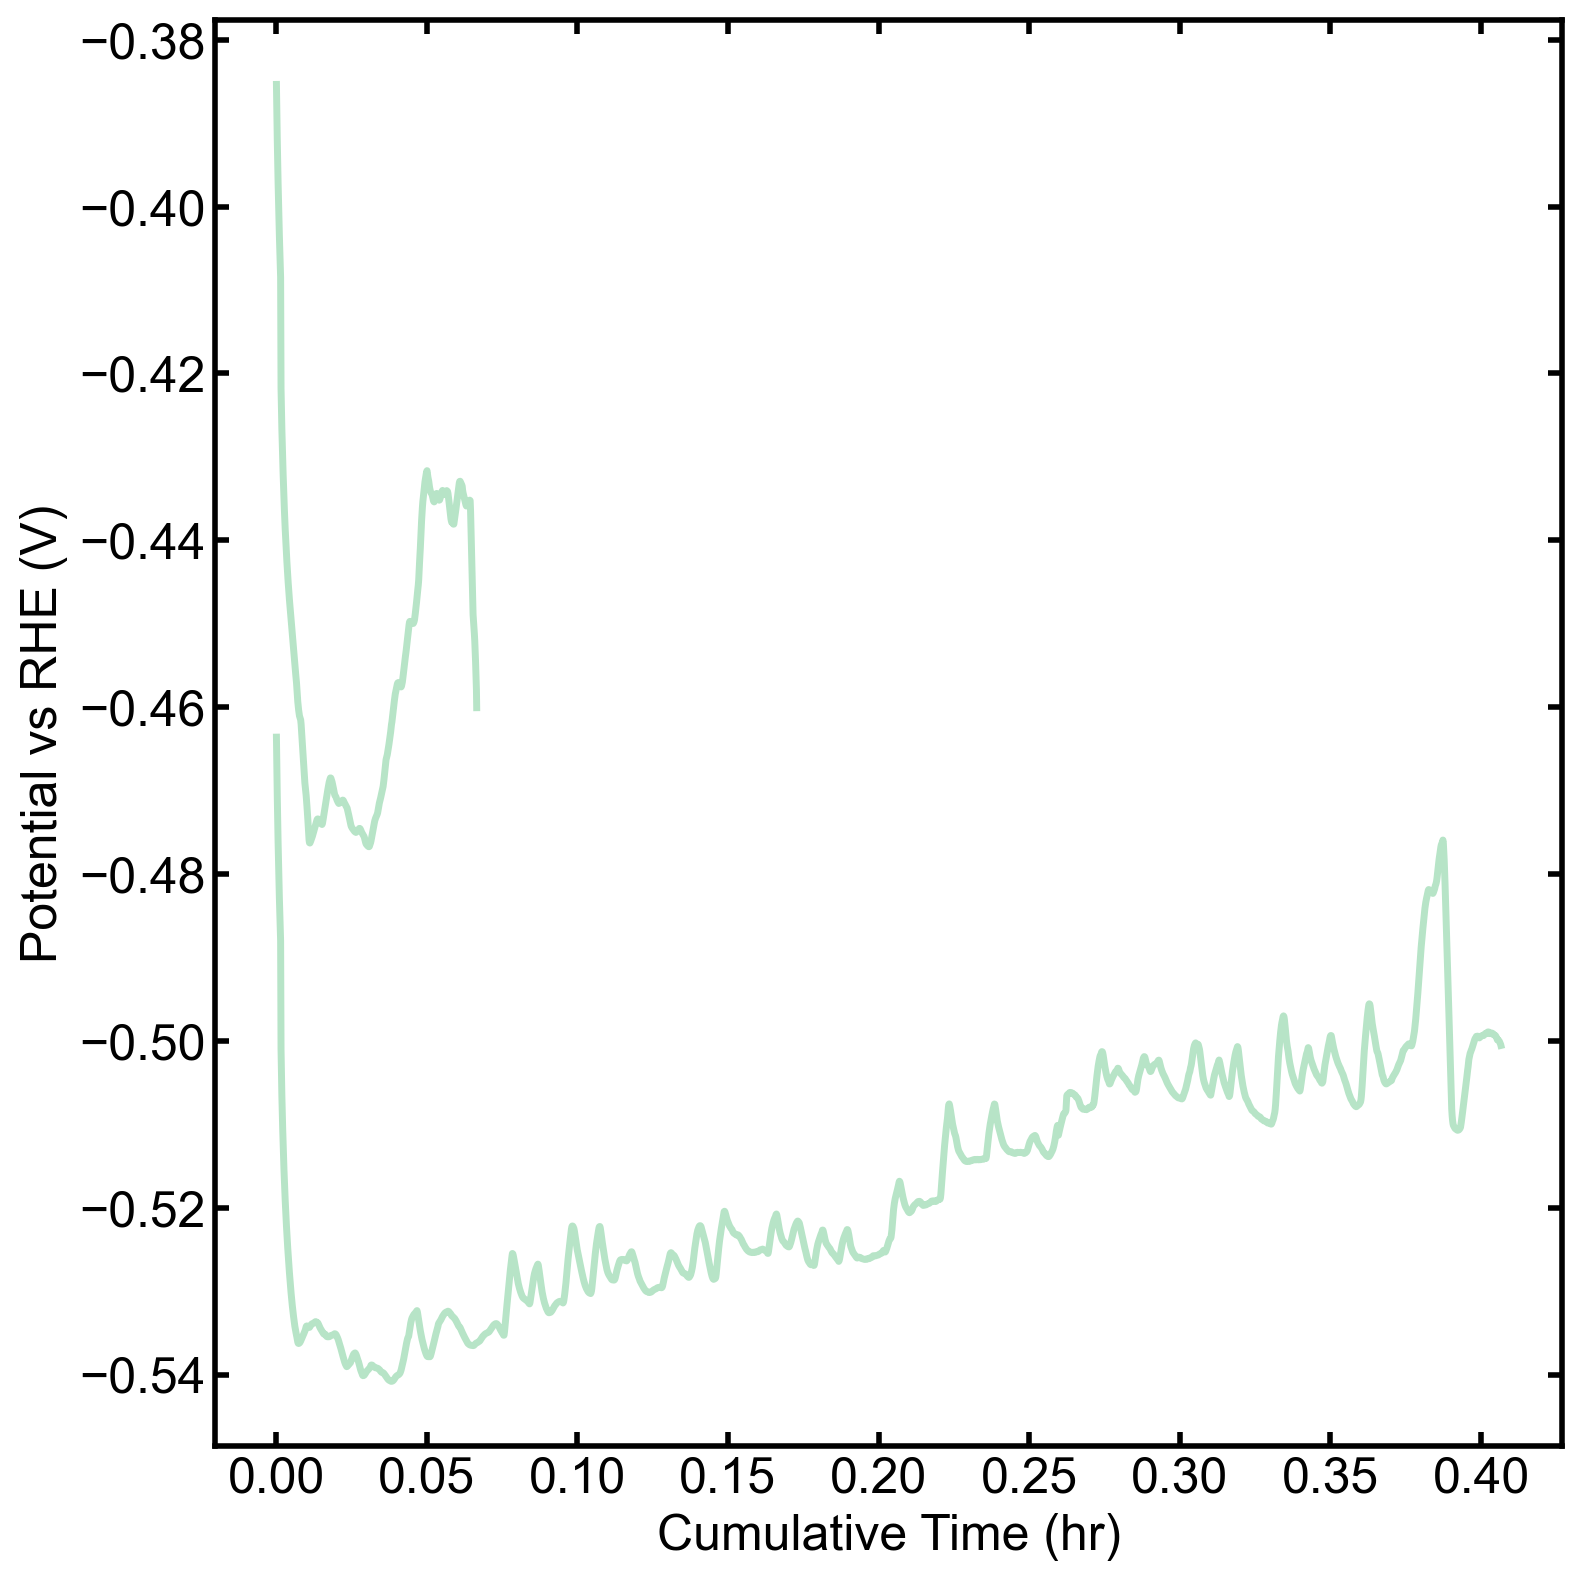

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import io
import os

# --- Plotting Setup ---
time_offset_hours = 0.0

plot_labels = [
    '-3 mA light FR',
    '_nolegend_',
    '-3 mA light FR',
    '_nolegend_',
    '_nolegend_',
]

# Setting our figure size
plt.figure(figsize=(8, 8))
plt.grid(False)

# Standard reference electrode potential and pH conversions
ref = 0.197     # Standard reference electrode potential
pH = 6.8        # pH of the solution
refi = ref + 0.059 * pH  # Conversion factor to RHE (V)

# Filtering & Smoothing Parameters
VALID_VOLTAGE_MIN = -1.9
VALID_VOLTAGE_MAX = 0.0
WINDOW_SIZE = 20
colors = ['#b7e4c7','#74c69d','#74c69d', '#74c69d',]
colors = ['#b7e4c7','#74c69d','#40916c', '#1b4332']
cmap = ['#b7e4c7','#b7e4c7', '#1b4332','b', 'g', 'm', 'm', 'm', 'c', 'y']
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# IMPORTANT NOTE:
# This script assumes that the variable `filelist_MV782n2_OCV` is a list
# of valid file paths that `pd.read_csv` can access in your local environment.
# ==========================================

# Make sure this variable is defined and points to your real files
# Example:
# filelist_MV782n2_OCV = ['path/to/file1.csv', 'path/to/file2.csv', ...]
VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 0
plt.figure(figsize=(8, 8))
plt.grid(False)

# --- Constants & Setup ---
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
time_offset_hours = 0.0



# --- Plotting Loop with Filtering ---
print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

for jj in range(len(filelist2)):
    skip = 54 
    # 1. Read your actual data file
    df = pd.read_csv(filelist2[jj], skiprows=skip, encoding="ISO-8859-1", delimiter='\t')


# Step 1: Filter out invalid voltage readings BEFORE smoothing
    df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
    
    # Step 2: Calculate the smoothed voltage on the FILTERED data
    df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(window=WINDOW_SIZE, center=True, min_periods=1).mean()
    
    # Step 3: Plot the cleaned and smoothed data
    # FIX 1: We calculate time using df_filtered so the row count matches voltage_smooth
    current_time_hours = df_filtered['time/s'] / 3600

    x_values = current_time_hours 
    
    current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj}'
    
    # Plot the smoothed data (thicker, solid line)
    # FIX 2: Removed [jj] index from current_label to pass the correct string
    plt.plot(
        x_values, 
        df_filtered['voltage_smooth'] + refi, 
        color=cmap[jj % len(cmap)], 
        linewidth=2.5, 
        label=current_label
    )
    if not current_time_hours.empty:
        time_offset_hours += current_time_hours.max()
# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend()
plt.tight_layout()
#plt.ylim(-0.8, -0.55)
plt.savefig("zoomed_voltage_after_ocv.pdf", format="pdf", bbox_inches="tight")

plt.show()




In [38]:
filelist_1= sorted(glob.glob('*.mpt'))
#FR_filelist
filelist_1 = '20240612_3TTiAg#1_plain_CV_1sun_with_glass_1_C01.mpt','20240612_3TTiAg#1_plain_OCV_1sun_no_glass_2_02_CV_C01.mpt'

Filtering out data points outside the range: -10.0V to 0.0V


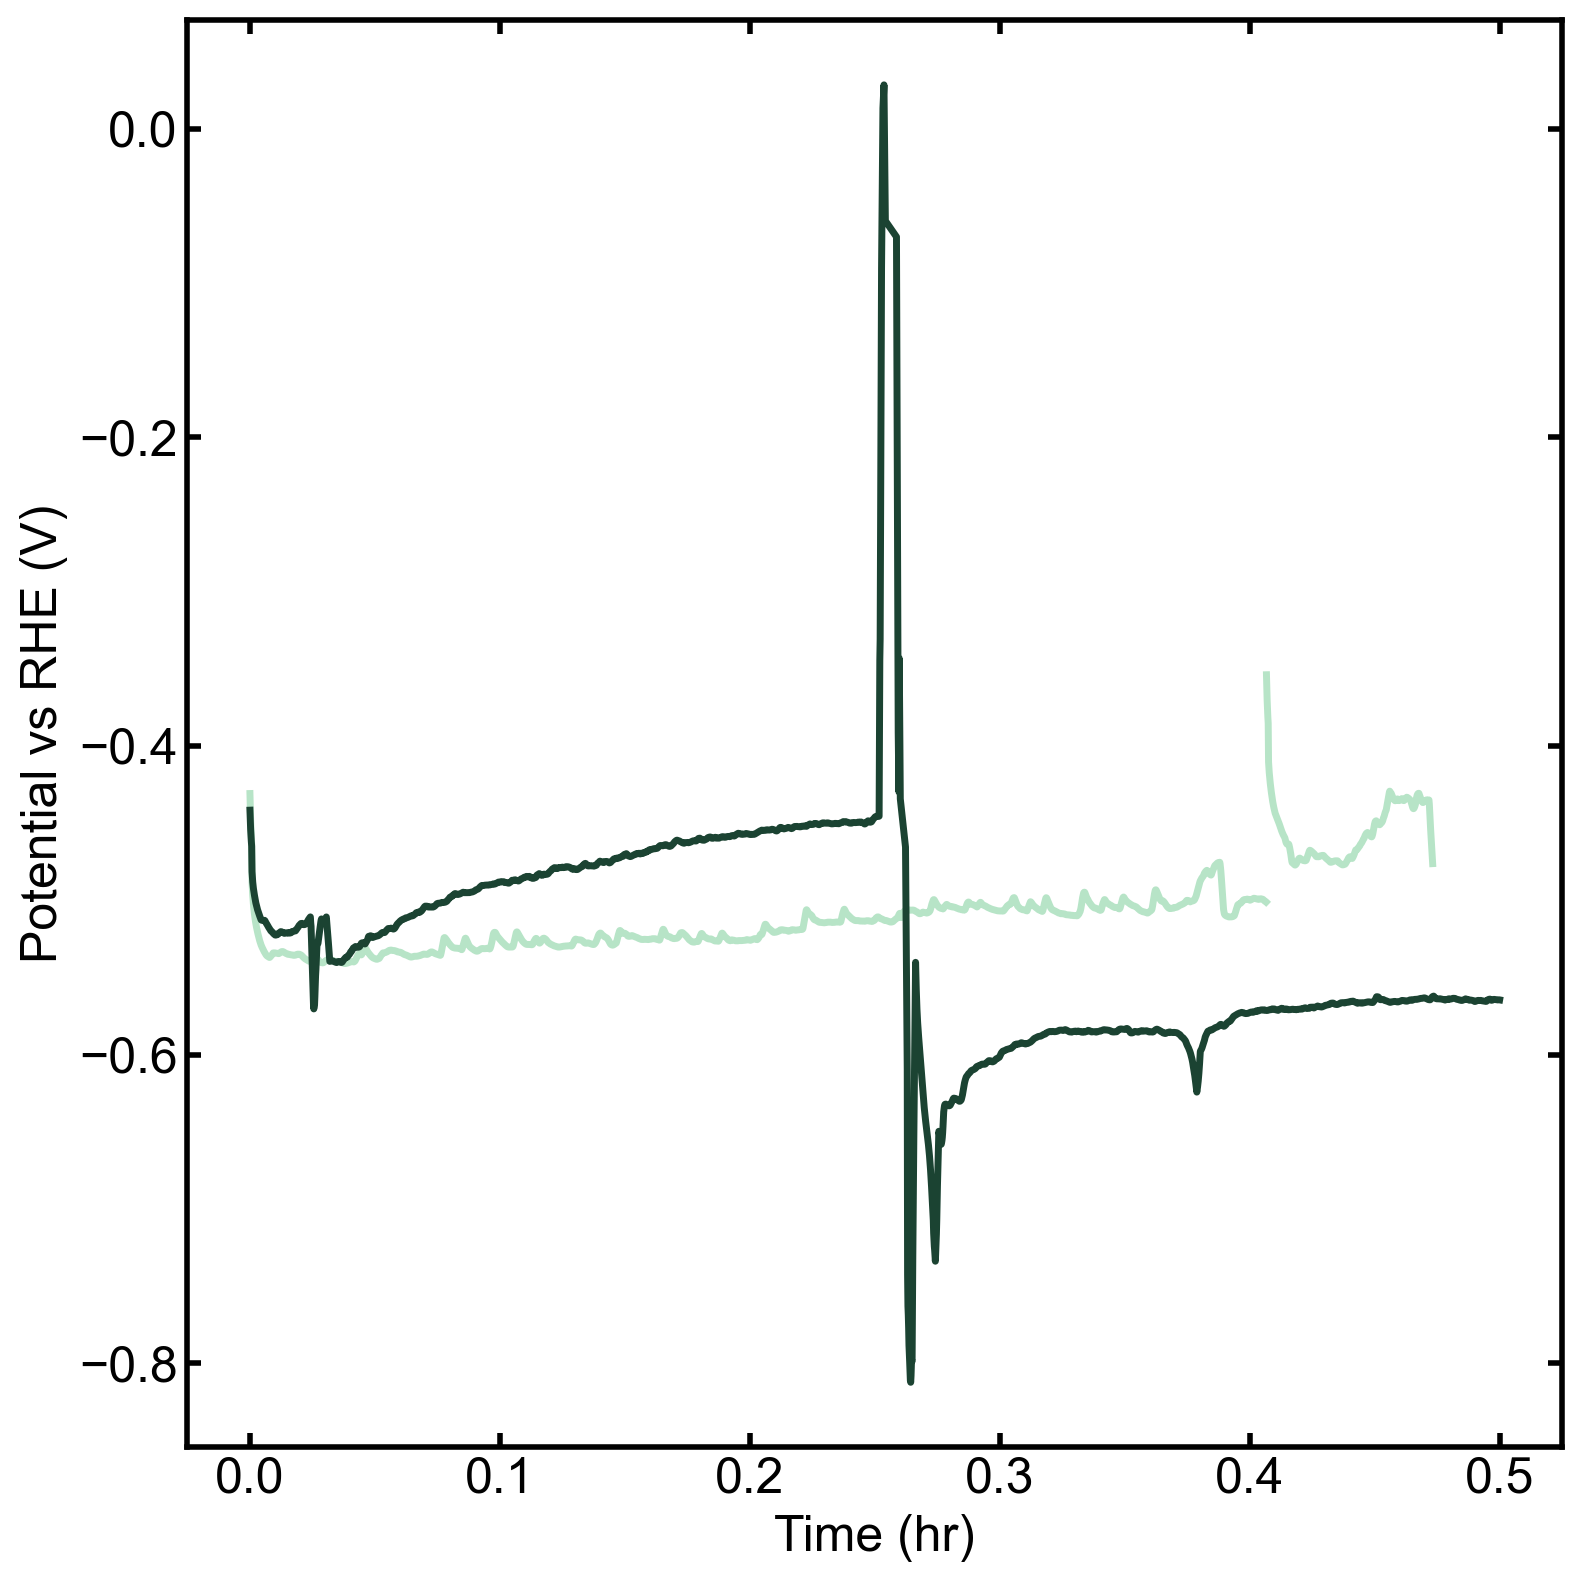

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# This script assumes 'filelist_run12' and 'filelist_run3' are lists of file paths.
# Since the files were not provided, I have created dummy files for demonstration.
# Please replace these with your actual file lists.

filelist2 = [
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_part2_C01.mpt',

           ]
filelist3= [ '20260811_3TAgsdgrid_aglayer_803dep_ce_ccloth2_re_agagcl_withco2flow_8mlmin_1sun_FR_n3mA_CP_C01.mpt']

# --- Plotting Setup ---
plt.figure(figsize=(8, 8))
plt.grid(False)

# Standard reference electrode potential and pH conversions
ref = 0.197     # Standard reference electrode potential
pH = 6.8        # pH of the solution
refi = ref + 0.059 * pH  # Conversion factor to RHE (V)

# Filtering & Smoothing Parameters
VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 0.0
WINDOW_SIZE = 10 # Using a smaller window for dummy data

# Define colors and labels
colors = ['#b7e4c7','#b7e4c7', '#1b4332']
labels = ['Run 1', 'Run 2', 'Run 3']

print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

# --- Plot Runs 1 and 2 Sequentially ---
time_offset_hours = 0.0
for i, filepath in enumerate(filelist2):
    df = pd.read_csv(filepath, skiprows=54, encoding="ISO-8859-1", delimiter='\t')
    
    # Filter, smooth, and plot
    df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
    df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(window=WINDOW_SIZE, center=True, min_periods=1).mean()
    
    current_time_hours = df_filtered['time/s'] / 3600
    x_values = current_time_hours + time_offset_hours
    
    plt.plot(
        x_values, 
        df_filtered['voltage_smooth'] + refi, 
        color=colors[i], 
        linewidth=2.5, 
        label=labels[i]
    )
    
    if not current_time_hours.empty:
        time_offset_hours += current_time_hours.max()

# --- Plot Run 3 Overlaid ---
for filepath in filelist3:
    df = pd.read_csv(filepath, skiprows=54, encoding="ISO-8859-1", delimiter='\t')
    
    # Filter, smooth, and plot
    df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
    df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(window=WINDOW_SIZE, center=True, min_periods=1).mean()
    
    # Plot without the time offset
    current_time_hours = df_filtered['time/s'] / 3600
    x_values = current_time_hours
    
    plt.plot(
        x_values, 
        df_filtered['voltage_smooth'] + refi, 
        color=colors[2], # Use the third color
        linewidth=2.5, 
        label=labels[2] # Use the third label
    )

# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend(fontsize=14)
plt.tight_layout()
plt.savefig("zoom_CP_FR_CP.pdf", format="pdf", bbox_inches="tight")
plt.show()

